# 2D Co-inversion and Inhomogeneous Resistivity
Here we use the adaptive-kernel 2D coinverter together with our inhomogeneous Ohmic solver to illustrate how inhomogeneous metallic current flows can be reconstructed in sottools.

As always, we begin with importing the required modules and defining a representative test SQUID. The SQUID is is of a realistic size and height close to that used in our [Kagome paper](https://arxiv.org/abs/2606.20157).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from prompt_toolkit.key_binding.bindings.named_commands import backward_char

import sottools.forward as forward
import sottools.mesh as mesh
from sottools import backward
import sottools.utils.meshplotting as meshplotting

params = forward.Forward2DParameters(
    Lx = 6.0,
    Ly = 6.0,
    Nx = 128,
    Ny = 128, # Take care: pixels must be PERFECTLY square
    rho1 = 0.1,
    rho2 = 0.24,
    height = 0.35,
    phi = np.deg2rad(63.0), # Standard TM-SOT sensor tilt angle
    invert_normal=True # Sets the sign of the SQUID response
)
fwd = forward.Forward2DCurrent(params)

Now we define the geometry. We use a single test geometry for all 2D showcases. To smooth out simulation artifacts, we round the corners, which takes a bit of finesse:

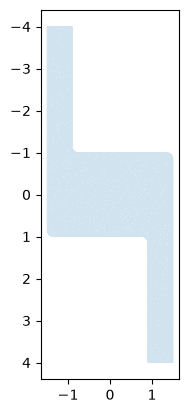

In [2]:
def corner_block_geometry(
    W: float = 3.0,
    H: float = 3.0,
    lead_width: float = 0.6,
    lead_length: float = 2.0,
    corner_radius: float = 0.15,
    n_arc: int = 8,
):
    BM = mesh.SimplyConnectedCurrentMesh.BoundaryMarker
    w, L = lead_width, lead_length
    if not (0 < w < min(W, H)):
        raise ValueError("lead_width must be positive and smaller than the block.")

    # Counter-clockwise polygon: (point, marker of the segment starting here, may round?)
    corners = [
        ((-L, 0.0), BM.DIRICHLET_LEFT, False),      # inlet lead, bottom wall starts
        ((W, 0.0), BM.DIRICHLET_LEFT, True),        # block bottom-right (convex)
        ((W, H - w), BM.DIRICHLET_LEFT, True),      # re-entrant corner into outlet lead
        ((W + L, H - w), BM.NEUMANN_OUT, False),    # outlet (open end)
        ((W + L, H), BM.DIRICHLET_RIGHT, False),
        ((0.0, H), BM.DIRICHLET_RIGHT, True),       # block top-left (convex)
        ((0.0, w), BM.DIRICHLET_RIGHT, True),       # re-entrant corner into inlet lead
        ((-L, w), BM.NEUMANN_IN, False),            # inlet (open end)
    ]

    points, markers = [], []
    n = len(corners)
    for i, (p, marker_out, roundable) in enumerate(corners):
        p = np.asarray(p, dtype=float)
        if not roundable or corner_radius <= 0:
            points.append(p)
            markers.append(marker_out)
            continue

        # Fillet tangent to both edges: unit vectors towards the neighbouring corners
        p_prev = np.asarray(corners[i - 1][0], dtype=float)
        p_next = np.asarray(corners[(i + 1) % n][0], dtype=float)
        a = (p_prev - p) / np.linalg.norm(p_prev - p)
        b = (p_next - p) / np.linalg.norm(p_next - p)
        theta = np.arccos(np.clip(a @ b, -1.0, 1.0))           # angle between the edges
        t = corner_radius / np.tan(theta / 2)                    # corner to tangent point
        if t > 0.5 * min(np.linalg.norm(p_prev - p), np.linalg.norm(p_next - p)):
            raise ValueError(f"corner_radius too large for the corner at {tuple(p)}.")
        centre = p + (a + b) / np.linalg.norm(a + b) * corner_radius / np.sin(theta / 2)
        T1, T2 = p + a * t, p + b * t
        phi1 = np.arctan2(T1[1] - centre[1], T1[0] - centre[0])
        phi2 = np.arctan2(T2[1] - centre[1], T2[0] - centre[0])
        dphi = (phi2 - phi1 + np.pi) % (2 * np.pi) - np.pi      # short way round
        for k in range(n_arc + 1):
            phi = phi1 + dphi * k / n_arc
            points.append(centre + corner_radius * np.array([np.cos(phi), np.sin(phi)]))
            markers.append(marker_out)   # both edges at a rounded corner are the same wall

    # Visual frame (h, u) -> mesh coordinates [x, y] = [-u, h]
    vertices = [[h, u] for h, u in points]
    segments = [[i, (i + 1) % len(vertices)] for i in range(len(vertices))]

    cx, cy = np.mean(vertices, axis=0)
    vertices = [([x-cx, y-cy]) for x, y in vertices]
    return vertices, segments, markers

vertices, segments, segment_markers = corner_block_geometry(W=2.0, H=3.0, lead_length=3.0)
blockmesh = mesh.SimplyConnectedCurrentMesh(
    vertices, segments, segment_markers, max_area=4e-4, refine_distance=0.01
)

fig, ax = plt.subplots(1,1)
meshplotting.plot_mesh(blockmesh, ax, alpha=.2, lw=.2)
plt.show()

Now we build the solver. We use a high resolution mesh (made above) to solve to high accuracy---this can take a while. We make the same of uniform resistivity, with a low-$\rho$ oval in the centre. An analogous thin film system could be a Pt structure with a copper oval deposited on top. Note that sottools works best when keeping units of um, uA, uT.

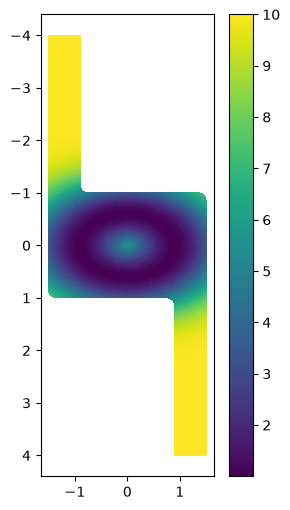

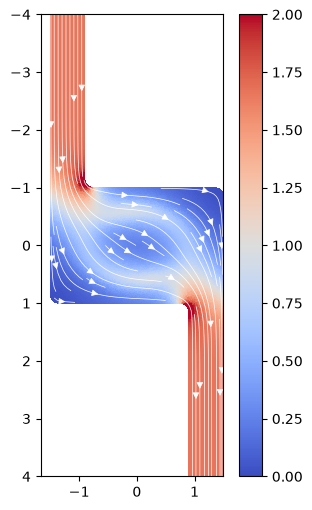

In [3]:
xt, yt = blockmesh.centers.T
R = np.sqrt(xt ** 2 + yt ** 2)
r = .6
sigma = .5
a = 1.5  # stretch factor along y
R_eff = np.sqrt(xt**2 + (yt / a)**2)
rho = 10-9*np.exp(-(R_eff-r)**2/(2*sigma**2))

fig, ax = plt.subplots(1,1,figsize=(4,6))
meshplotting.plot_tc_field(blockmesh, ax, rho)
plt.show()

solver = mesh.InhomogeneousOhmicSolver(blockmesh, rho)
res = solver.solve(left_bc=0.0, right_bc=1.0)

fig, ax = plt.subplots(1,1, figsize=(4,6))
meshplotting.streamplot(blockmesh, ax, res["Kx"], res["Ky"], n_grid=256, density=1.5, cmap='coolwarm', vmin=0.0, vmax=2.0)
plt.show()


We can use the forward object to now calculate the corresponding signal, and try to invert this. However, spuriously, some information about the mesh might end up in this signal. The inversion must be performed on a different, independent mesh. Consequently, we must make a second mesh, slightly perturbed from the original, perfect one.

In normal fixed-kernel inversion, we can immediately make a "coarse" mesh that is still quite fine, and in this way achieve an accurate reconstruction right away. With co-inversion, one intermediate step is required. Because the co-inversion algorithm is computationally very expensive, we first make a mesh that is extremely coarse. The current inversion thereon will not be good---it will be very smooth and it will not capture any fine detail. But, because our kernel is generally quite wide, it captures the features of the kernel just fine, and we will see that an extremely coarse mesh can still recapture the kernel parameters to 1 percent, even in presence of noise.

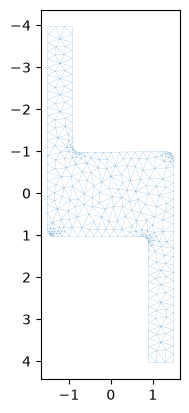

The very coarse mesh has 358 vertices.


In [4]:
rng = np.random.default_rng(42)
sigma = 0.01
offsetx, offsety = rng.uniform(-0.05, 0.05, size=2)
vertices_perturbed = [([x+rng.normal(0.0, sigma) + offsetx, y+rng.normal(0.0, sigma) + offsety]) for x,y in vertices]
blockmesh_perturbed_verycoarse = mesh.SimplyConnectedCurrentMesh(vertices_perturbed, segments, segment_markers, max_area=4e-2, refine_distance=0.2)

fig, ax = plt.subplots(1,1)
meshplotting.plot_mesh(blockmesh_perturbed_verycoarse, ax, alpha=.5, lw=.2)
plt.show()

print(f"The very coarse mesh has {blockmesh_perturbed_verycoarse.vertices.shape[0]} vertices.")

Armed with both meshes, we can generate the raw signal and immediately use a backward.Coinversion2D object to find the best kernel parameters. This takes about 1 minte on a strong CPU.

In [5]:
m2g_true = forward.MeshToGrid(blockmesh, params)
m2g_perturbed_verycoarse = forward.MeshToGrid(blockmesh_perturbed_verycoarse, params)
signal_raw = fwd.forward(*m2g_true.streamfunction_to_currents(res["streamfunction"]))
conv_checker = backward.CoinversionConvergenceChecker(
    objtol = 1e-6,
    fidtol = 1e-6,
    heighttol = 1e-3,
    phitol = np.deg2rad(0.01),
    nwindow=10,
    nextrapolate=50,
)
coinverter = backward.Coinversion2D(
    m2g_perturbed_verycoarse,
    fwd,
    signal_raw,
    lam1=1e-11,
    lam2=1e-10,
    lam3=1e-15,
    initial_height = 1.0,
    initial_phi_eff = np.deg2rad(45.0),
    lumped_mass=True,
    crossvalidation_size = 2,
    convergence_checker = conv_checker,
    lr_current = 1,
    cache_kernels=True,
    use_cg=True,
    verbose=True
)
coinverter_fitres = coinverter.fit(n_steps_sensor=500, n_steps_current=500)

Starting co-inversion with 500 sensor optimization steps and 500 current optimization steps per sensor step.
Optimizing sensor parameters.
Evaluation 1: optimizing fold currents.
	 Caching kernels into forward model.
	 Optimizing current for each fold.


	 Starting v calculation.


	 CG finished in 56 iterations with relative residual 7.29e-03 in 2.6257 s.


	 CG finished in 55 iterations with relative residual 7.13e-03 in 0.9829 s.


Evaluation 2: optimizing fold currents.
	 Caching kernels into forward model.
	 Optimizing current for each fold.


...

	 CG finished in 8 iterations with relative residual 7.39e-03 in 0.2515 s.


	 CG finished in 8 iterations with relative residual 8.98e-03 in 0.4537 s.


Evaluation 23: optimizing fold currents.
	 Caching kernels into forward model.
	 Optimizing current for each fold.
	 Starting v calculation.


	 CG finished in 0 iterations with relative residual 9.95e-03 in 0.0236 s.
	 CG finished in 5 iterations with relative residual 6.98e-03 in 0.1620 s.


Iteration 12: h = 0.3514, phi_eff = 63.065 deg
FIT FINISHED --- TIMING SUMMARY
CURRENT DETERMINATION --- 	Average: 9.9975 s	Max: 33.4502 s	Min: 0.1389	Total: 229.9434 s
V CALCULATION --- 	Average: 8.5343 s	Max: 34.6027 s	Min: 0.2488	Total: 196.2896 s
SENSOR DETERMINATION --- 	Total: 457.9236 s
HISTORY RECORDING --- 		Average: 0.2678 s	Max: 1.0961 s	Min: 0.1606	Total: 6.1598 s


To verify the fit worked well, we can plot both the original signal and the fitted signal side-by-side. As we added no noise, and the regularizers are rather light, these should correspond well. The only action of the regularizer can be to smoothen a bit within a single kernel size.

In [6]:
final_parameters = coinverter_fitres["final_sensor_parameters"]
determined_height = final_parameters[0]
determined_phi = np.rad2deg(final_parameters[3])
print("Determined height:\t", round(determined_height, 4), "um\tTrue height:\t", params.height, "um\tError:\t", round(determined_height-params.height, 4), "um")
print("Determined phi:\t\t", round(determined_phi, 4), "deg\tTrue phi:\t\t", np.rad2deg(params.phi), "deg\tError:\t", round(determined_phi-np.rad2deg(params.phi), 4), "deg")

Determined height:	 0.3514 um	True height:	 0.35 um	Error:	 0.0014 um
Determined phi:		 63.0652 deg	True phi:		 63.0 deg	Error:	 0.0652 deg


We can also compare the original signal and the fitted signal: although there is very little structure available to the solver, due to the width of the kernel, a good fit is achieved that clearly minimizes the CV score.

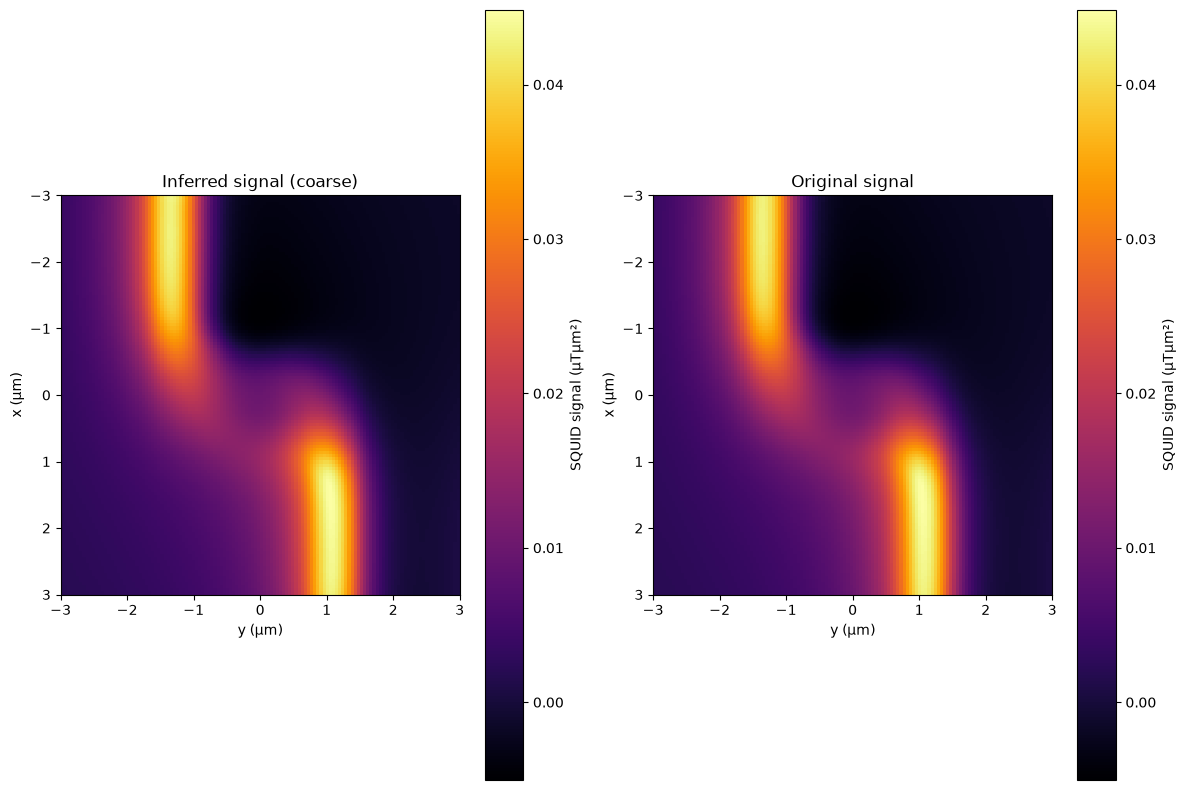

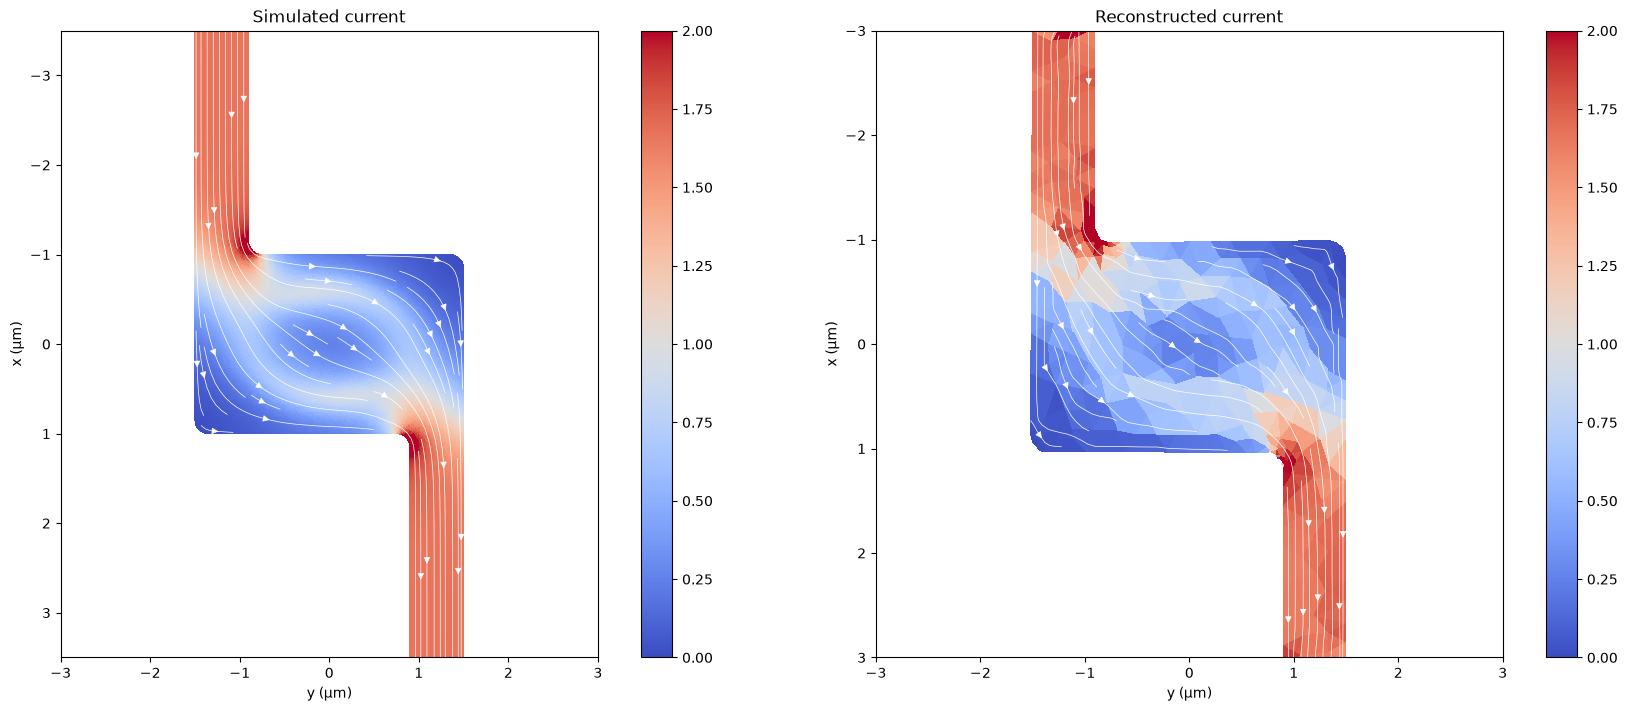

In [7]:
signal_predicted_coinverter = coinverter.prediction
fitted_streamfunction = coinverter.fitted_streamfunction
Kx, Ky = blockmesh_perturbed_verycoarse.field_curl(fitted_streamfunction)
fig, (ax_infer, ax_true) = plt.subplots(1,2,figsize=(12,8))
im0 = ax_infer.imshow(signal_predicted_coinverter, extent=[-params.Ly / 2, params.Ly / 2, params.Lx / 2, -params.Lx / 2], cmap='inferno')
ax_infer.set_xlabel('y (µm)')
ax_infer.set_ylabel('x (µm)')
ax_infer.set_aspect('equal')
ax_infer.set_title("Inferred signal (coarse)")
im1 = ax_true.imshow(signal_raw, extent=[-params.Ly / 2, params.Ly / 2, params.Lx / 2, -params.Lx / 2], cmap='inferno')
ax_true.set_xlabel('y (µm)')
ax_true.set_ylabel('x (µm)')
ax_true.set_aspect('equal')
ax_true.set_title("Original signal")
plt.colorbar(im0, ax=ax_infer, label='SQUID signal (µTµm²)')
plt.colorbar(im0, ax=ax_true, label='SQUID signal (µTµm²)')
plt.tight_layout()
plt.show()

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(18, 7), layout="constrained")

# Left: simulated current on the original mesh, 6 um wide by 7 um tall, centred on the device
V = blockmesh.vertices
xc = 0.5 * (V[:, 0].min() + V[:, 0].max())   # vertical centre (x points down)
yc = 0.5 * (V[:, 1].min() + V[:, 1].max())   # horizontal centre
meshplotting.streamplot(blockmesh, ax0, res["Kx"], res["Ky"], n_grid=256, density=1.5,
                        cmap="coolwarm", vmin=0.0, vmax=2)
ax0.set_xlim(yc - 3.0, yc + 3.0)
ax0.set_ylim(xc + 3.5, xc - 3.5)             # 7 um tall, x pointing down
ax0.set_title("Simulated current")

# Right: reconstructed current on the perturbed mesh, same 6 x 6 um window as the signal
meshplotting.streamplot(blockmesh_perturbed_verycoarse, ax1, Kx, Ky, n_grid=256,
                        density=1.5, cmap="coolwarm", vmin=0.0, vmax=2)
ax1.set_xlim(-params.Ly / 2, params.Ly / 2)
ax1.set_ylim(params.Lx / 2, -params.Lx / 2)  # x pointing down
ax1.set_title("Reconstructed current")

for ax in (ax0, ax1):
    ax.set_xlabel("y (µm)")
    ax.set_ylabel("x (µm)")
plt.show()


Then we can use these determined parameters and a less coarse mesh to perform the final inversion.

In [8]:
blockmesh_perturbed = mesh.SimplyConnectedCurrentMesh(vertices_perturbed, segments, segment_markers, max_area=1e-3, refine_distance=0.03)
fwdparams_inferred = forward.Forward2DParameters(
    Lx = params.Lx,
    Ly = params.Ly,
    Nx = params.Nx,
    Ny = params.Ny,
    rho1 = params.rho1,
    rho2 = params.rho2,
    height = determined_height,
    phi = np.deg2rad(determined_phi),
    invert_normal=True
)
m2g_perturbed = forward.MeshToGrid(blockmesh_perturbed, fwdparams_inferred)
inverter = backward.Inverter2D(m2g_perturbed, fwd, signal_raw, lam1=1e-11, lam2=1e-10, lam3=1e-15, lumped_mass=True)
inverter_fitres = inverter.fit(lr=1.0, n_steps=200)

To finish, we plot, and find a good reconstruction (similar to the fixed-kernel inversion).

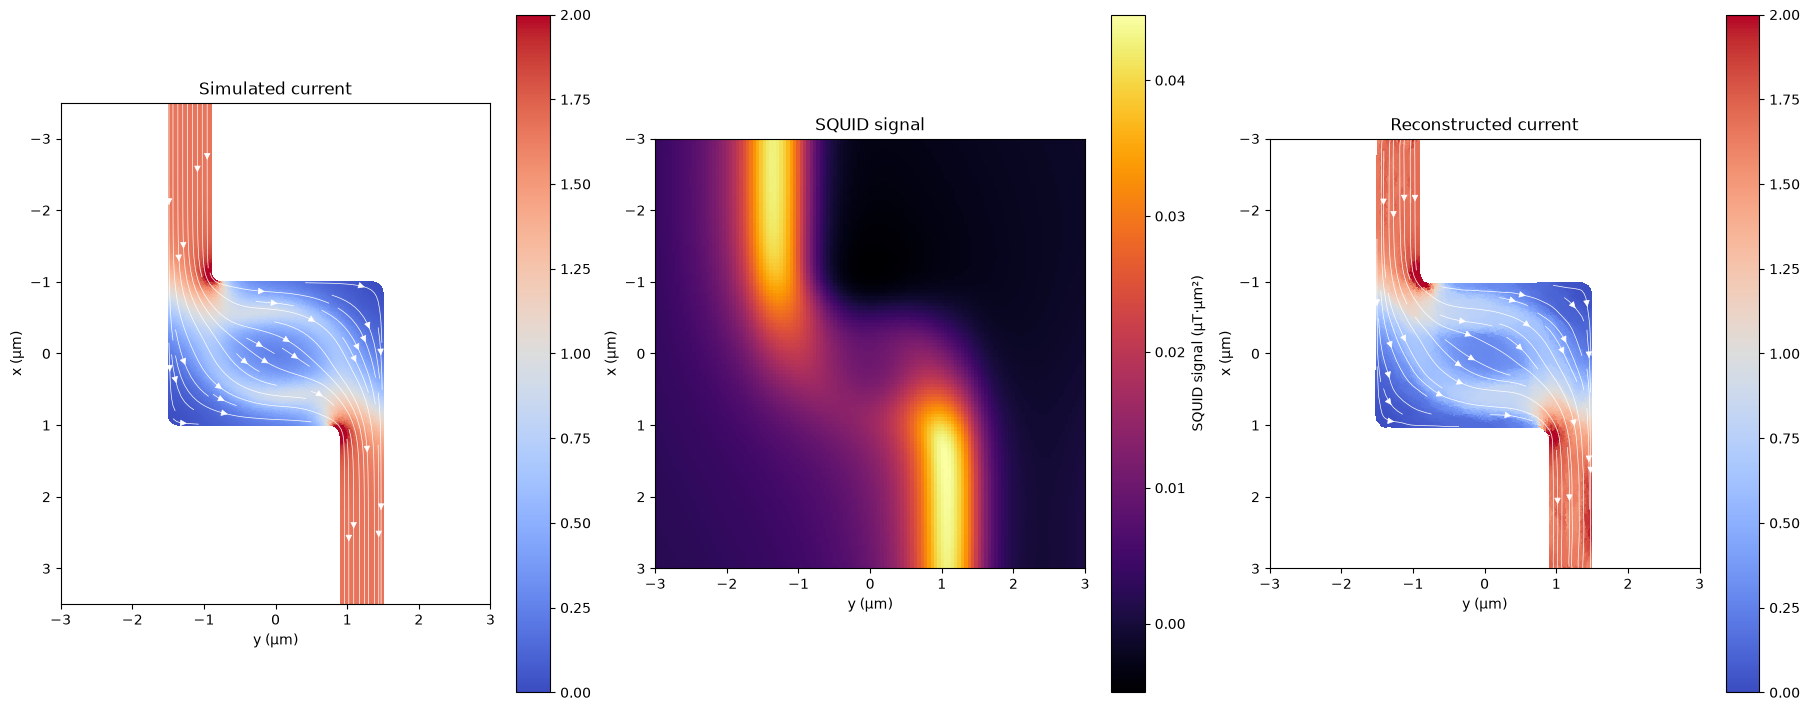

In [9]:
fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(18, 7), layout="constrained")

# Left: simulated current on the original mesh, 6 um wide by 7 um tall, centred on the device
V = blockmesh.vertices
xc = 0.5 * (V[:, 0].min() + V[:, 0].max())   # vertical centre (x points down)
yc = 0.5 * (V[:, 1].min() + V[:, 1].max())   # horizontal centre
meshplotting.streamplot(blockmesh, ax0, res["Kx"], res["Ky"], n_grid=256, density=1.5,
                        cmap="coolwarm", vmin=0.0, vmax=2)
ax0.set_xlim(yc - 3.0, yc + 3.0)
ax0.set_ylim(xc + 3.5, xc - 3.5)             # 7 um tall, x pointing down
ax0.set_title("Simulated current")

# Middle: the SQUID signal on the 6 x 6 um scan window
im = ax1.imshow(signal_raw, extent=[-params.Ly / 2, params.Ly / 2, params.Lx / 2, -params.Lx / 2],
                cmap="inferno")
ax1.set_aspect("equal")
plt.colorbar(im, ax=ax1, label="SQUID signal (µT·µm²)")
ax1.set_title("SQUID signal")

# Right: reconstructed current on the perturbed mesh, same 6 x 6 um window as the signal
meshplotting.streamplot(blockmesh_perturbed, ax2, inverter_fitres["Kx"], inverter_fitres["Ky"], n_grid=256,
                        density=1.5, cmap="coolwarm", vmin=0.0, vmax=2)
ax2.set_xlim(-params.Ly / 2, params.Ly / 2)
ax2.set_ylim(params.Lx / 2, -params.Lx / 2)  # x pointing down
ax2.set_title("Reconstructed current")

for ax in (ax0, ax1, ax2):
    ax.set_xlabel("y (µm)")
    ax.set_ylabel("x (µm)")
plt.show()

Does noise change this? Adding SNR=40 noise shows, and rerunning the whole chain shows that the co-inversion chain is robust against Gaussian noise.

In [10]:
rng = np.random.default_rng(42)
snr = 40
sigma = np.ptp(signal_raw) / snr
noise = rng.normal(0.0, sigma, size=signal_raw.shape)
signal_noisy = signal_raw + noise

coinverter_noisy = backward.Coinversion2D(
    m2g_perturbed_verycoarse,
    fwd,
    signal_noisy,
    lam1=1e-11,
    lam2=1e-10,
    lam3=1e-15,
    initial_height=1.0,
    initial_phi_eff=np.deg2rad(45.0),
    lumped_mass=True,
    crossvalidation_size=2,
    convergence_checker=conv_checker,
    lr_current=1,
    cache_kernels=True,
    use_cg=True,
    verbose=True
)
coinverter_noisy_fitres = coinverter_noisy.fit(n_steps_sensor=500, n_steps_current=500)

Starting co-inversion with 500 sensor optimization steps and 500 current optimization steps per sensor step.
Optimizing sensor parameters.
Evaluation 1: optimizing fold currents.
	 Caching kernels into forward model.


	 Optimizing current for each fold.


	 Starting v calculation.


	 CG finished in 53 iterations with relative residual 9.77e-03 in 4.3349 s.


	 CG finished in 58 iterations with relative residual 6.03e-03 in 3.9997 s.


...

Evaluation 22: optimizing fold currents.
	 Caching kernels into forward model.
	 Optimizing current for each fold.


	 Starting v calculation.
	 CG finished in 1 iterations with relative residual 8.11e-03 in 0.1126 s.


	 CG finished in 0 iterations with relative residual 6.96e-03 in 0.0764 s.


Iteration 12: h = 0.3518, phi_eff = 63.007 deg


FIT FINISHED --- TIMING SUMMARY
CURRENT DETERMINATION --- 	Average: 5.2934 s	Max: 11.6123 s	Min: 0.1588	Total: 116.4557 s
V CALCULATION --- 	Average: 3.1686 s	Max: 8.4122 s	Min: 0.2377	Total: 69.7101 s
SENSOR DETERMINATION --- 	Total: 214.7861 s
HISTORY RECORDING --- 		Average: 0.2639 s	Max: 1.4667 s	Min: 0.1336	Total: 5.8065 s


In [11]:
final_parameters = coinverter_noisy_fitres["final_sensor_parameters"]
determined_height = final_parameters[0]
determined_phi = np.rad2deg(final_parameters[3])
print("Determined height:\t", round(determined_height, 4), "um\tTrue height:\t", params.height, "um\tError:\t", round(determined_height-params.height, 4), "um")
print("Determined phi:\t\t", round(determined_phi, 4), "deg\tTrue phi:\t\t", np.rad2deg(params.phi), "deg\tError:\t", round(determined_phi-np.rad2deg(params.phi), 4), "deg")

Determined height:	 0.3518 um	True height:	 0.35 um	Error:	 0.0018 um
Determined phi:		 63.0075 deg	True phi:		 63.0 deg	Error:	 0.0075 deg


In [12]:
fwdparams_inferred_noisy = forward.Forward2DParameters(
    Lx = params.Lx,
    Ly = params.Ly,
    Nx = params.Nx,
    Ny = params.Ny,
    rho1 = params.rho1,
    rho2 = params.rho2,
    height = determined_height,
    phi = np.deg2rad(determined_phi),
    invert_normal=True
)
m2g_perturbed_noisy = forward.MeshToGrid(blockmesh_perturbed, fwdparams_inferred_noisy)
inverter_noisy = backward.Inverter2D(m2g_perturbed_noisy, fwd, signal_raw, lam1=1e-11, lam2=1e-10, lam3=1e-15, lumped_mass=True)
inverter_noisy_fitres = inverter_noisy.fit(lr=1.0, n_steps=200)

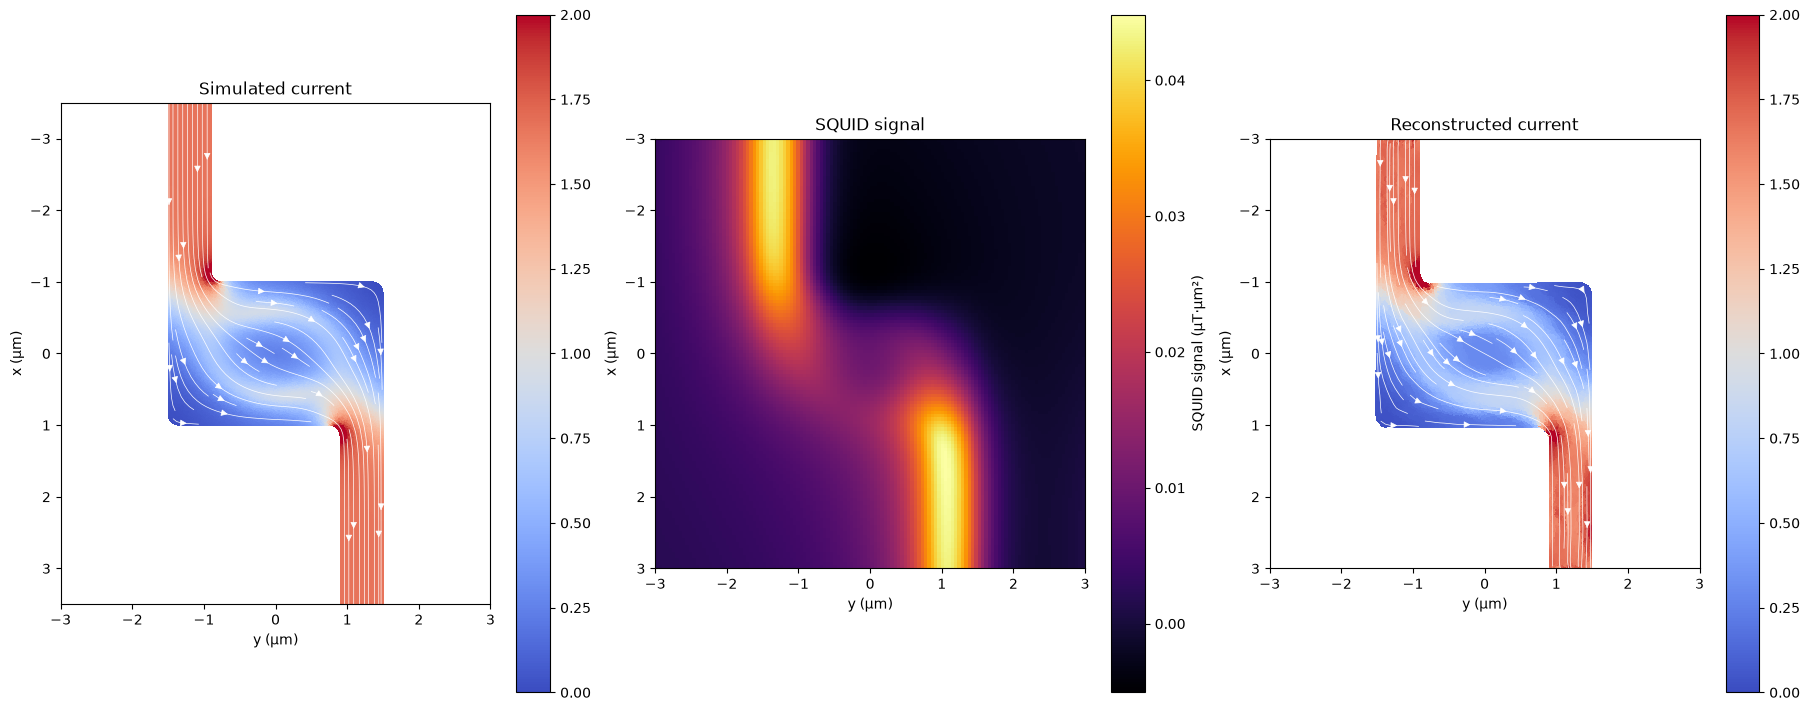

In [13]:
fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(18, 7), layout="constrained")

# Left: simulated current on the original mesh, 6 um wide by 7 um tall, centred on the device
V = blockmesh.vertices
xc = 0.5 * (V[:, 0].min() + V[:, 0].max())   # vertical centre (x points down)
yc = 0.5 * (V[:, 1].min() + V[:, 1].max())   # horizontal centre
meshplotting.streamplot(blockmesh, ax0, res["Kx"], res["Ky"], n_grid=256, density=1.5,
                        cmap="coolwarm", vmin=0.0, vmax=2)
ax0.set_xlim(yc - 3.0, yc + 3.0)
ax0.set_ylim(xc + 3.5, xc - 3.5)             # 7 um tall, x pointing down
ax0.set_title("Simulated current")

# Middle: the SQUID signal on the 6 x 6 um scan window
im = ax1.imshow(signal_raw, extent=[-params.Ly / 2, params.Ly / 2, params.Lx / 2, -params.Lx / 2],
                cmap="inferno")
ax1.set_aspect("equal")
plt.colorbar(im, ax=ax1, label="SQUID signal (µT·µm²)")
ax1.set_title("SQUID signal")

# Right: reconstructed current on the perturbed mesh, same 6 x 6 um window as the signal
meshplotting.streamplot(blockmesh_perturbed, ax2, inverter_noisy_fitres["Kx"], inverter_noisy_fitres["Ky"], n_grid=256,
                        density=1.5, cmap="coolwarm", vmin=0.0, vmax=2)
ax2.set_xlim(-params.Ly / 2, params.Ly / 2)
ax2.set_ylim(params.Lx / 2, -params.Lx / 2)  # x pointing down
ax2.set_title("Reconstructed current")

for ax in (ax0, ax1, ax2):
    ax.set_xlabel("y (µm)")
    ax.set_ylabel("x (µm)")
plt.show()